# exp02: Deep Learning Tabular

Menguji MLP, MLP residual, dan Transformer tabular pada fitur eye tracking dan fusion. Setiap window 15/25/45 detik diproses terpisah. Notebook mencakup training, pemilihan konfigurasi dengan validation, refit, evaluasi test, dan penyimpanan model.

Notebook ini mandiri: exp01 tidak perlu dijalankan terlebih dahulu. GPU T4 direkomendasikan.


## Lokasi data

Dataset dibaca langsung dari Google Drive. Path awal sudah diisi untuk folder proyek tim. Biarkan RESUME_DIR = None untuk run baru. Untuk melanjutkan, isi dengan path Run yang sebelumnya dicetak, lalu jalankan kembali dari atas. Tidak ada mode smoke/full.


In [1]:
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Penelitian-Adaptive-IDE")
DATASET_ROOT = PROJECT_ROOT / "Dataset" / "v2_session_phase"
RESUME_DIR = None
EXPERIMENT = "exp02"

## Environment

Cell ini memasang dependency yang diperlukan. Jika diminta restart, restart session dan jalankan kembali dari awal. Mount Drive menggunakan akun yang mempunyai izin Editor. Pintasan folder proyek di My Drive dapat digunakan. Environment harus cocok untuk resume; PyTorch/CUDA bawaan tidak diganti.


In [2]:
import importlib.metadata as _metadata
import importlib.util as _import_util
import subprocess
import sys

if sys.version_info < (3, 12):
    raise RuntimeError("Gunakan runtime Colab dengan Python 3.12 atau lebih baru.")

# Versi core sama pada kedua notebook; dependency dikelola di sini, tanpa file txt.
_required = {
    "numpy": "2.5.1",
    "pandas": "3.0.3",
    "scipy": "1.18.0",
    "scikit-learn": "1.9.1",
    "matplotlib": "3.11.0",
    "cloudpickle": "3.1.3",
}
if EXPERIMENT == "exp01":
    _required.update(
        {"imbalanced-learn": "0.14.2", "xgboost": "3.4.1", "catboost": "1.2.10"}
    )
_imports = {"scikit-learn": "sklearn", "imbalanced-learn": "imblearn"}
_changes = []
_restart = False
_current: str | None
for _name, _version in _required.items():
    try:
        _current = _metadata.version(_name)
    except _metadata.PackageNotFoundError:
        _current = None
    if _current != _version:
        _changes.append(f"{_name}=={_version}")
        _restart = _restart or _imports.get(_name, _name) in sys.modules
if _changes:
    print("Menyiapkan dependency:", ", ".join(_changes))
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "--quiet", *_changes]
    )  # nosec B603
    if _restart:
        raise RuntimeError(
            "Dependency diperbarui. Pilih Runtime > Restart session, lalu Run all kembali."
        )
if EXPERIMENT == "exp02" and _import_util.find_spec("torch") is None:
    raise RuntimeError(
        "PyTorch tidak tersedia. Gunakan runtime Colab standar yang sudah menyertakan PyTorch."
    )

if _import_util.find_spec("google.colab") is not None:
    from google.colab import drive

    drive.mount("/content/drive")

print("Dependency siap. Path proyek:", PROJECT_ROOT)

Mounted at /content/drive
Dependency siap. Path proyek: /content/drive/MyDrive/Penelitian-Adaptive-IDE


In [3]:
import copy
import hashlib
import io
import json
import platform
import random
import tempfile
import time
from datetime import UTC, datetime
from importlib import metadata
from pathlib import Path
from typing import Any

import cloudpickle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    PolynomialFeatures,
    RobustScaler,
    StandardScaler,
)

LABELS = ["Low", "Medium", "High"]
SEED = 42
CODE_VERSION = "batch03-1.0.0"
SENSOR_FEATURES = [
    "rmssd_ms",
    "sdnn_ms",
    "rmssd_baseline_ratio",
    "blink_count",
    "blink_rate_per_minute",
    "ear_left_mean",
    "ear_left_std",
    "ear_right_mean",
    "ear_right_std",
    "iris_size_estimate_mean",
    "iris_size_estimate_std",
    "iris_size_delta_mean",
    "iris_size_delta_std",
    "head_pitch_mean",
    "head_pitch_std",
    "head_yaw_mean",
    "head_yaw_std",
    "gaze_x_norm_mean",
    "gaze_x_norm_std",
    "gaze_y_norm_mean",
    "gaze_y_norm_std",
    "eye_state_fixation_ratio",
    "eye_state_saccade_ratio",
    "eye_state_transition_ratio",
    "eye_state_unclassified_ratio",
    "eye_state_other_ratio",
]
EYE_FEATURES = [
    f
    for f in SENSOR_FEATURES
    if f
    not in {
        "rmssd_ms",
        "sdnn_ms",
        "rmssd_baseline_ratio",
        "blink_count",
        "eye_state_other_ratio",
    }
]
GROUPS = {
    "eye": EYE_FEATURES,
    "hrv": ["rmssd_ms", "sdnn_ms"],
    "fusion": ["rmssd_ms", "sdnn_ms"] + EYE_FEATURES,
}


def canonical(value):
    return json.dumps(value, sort_keys=True, separators=(",", ":"), allow_nan=False)


def digest(value):
    return hashlib.sha256(canonical(value).encode()).hexdigest()


def metrics(y, probabilities):
    predicted = np.asarray(probabilities).argmax(axis=1)
    return {
        "accuracy": float(accuracy_score(y, predicted)),
        "macro_f1": float(
            f1_score(y, predicted, labels=[0, 1, 2], average="macro", zero_division=0)
        ),
        "balanced_accuracy": float(balanced_accuracy_score(y, predicted)),
    }


def combine_probabilities(arrays, weights):
    values = [np.asarray(a, dtype=float) for a in arrays]
    weights = np.asarray(weights, dtype=float)
    if (
        not values
        or len(values) != len(weights)
        or any(a.shape != values[0].shape for a in values)
    ):
        raise ValueError("Bentuk probabilitas atau jumlah bobot tidak cocok.")
    if values[0].ndim != 2 or values[0].shape[1] != 3 or not np.isfinite(weights).all():
        raise ValueError("Probabilitas harus mempunyai tiga kolom kelas.")
    if (weights < 0).any() or weights.sum() <= 0:
        raise ValueError("Bobot ensemble tidak valid.")
    if any(
        not np.isfinite(a).all()
        or (a < 0).any()
        or not np.allclose(a.sum(axis=1), 1.0, atol=1e-5)
        for a in values
    ):
        raise ValueError("Probabilitas tidak valid.")
    return np.average(np.stack(values), axis=0, weights=weights)


def rank_key(record):
    score = record["validation"]
    return (
        -score["accuracy"],
        -score["macro_f1"],
        record.get("complexity", 1),
        record["id"],
    )


def dump_bundle(bundle):
    return cloudpickle.dumps(bundle)


def load_bundle(payload):
    # Muat hanya artefak yang dibuat tim sendiri, bukan file dari sumber tak dikenal.
    return cloudpickle.loads(payload)  # nosec B301


IMPLEMENTATION_HASH = "85ae8d2b158465174a08fec8e3aa2f89b36504bcd822a78a33479341eb30e3a0"

try:
    from IPython.display import display
except ImportError:
    display = print

## Pembagian training, validation, dan test

Blok waktu 120 detik dibagi dengan seed 42 dan keterwakilan kelas dominan blok, mendekati 70/15/15. Data orang yang sama boleh muncul pada ketiga bagian. Ini evaluasi blok campuran, bukan LOPO atau TimeSeriesSplit.

Semua pilihan window memakai penempatan endpoint yang sama. Rentang pendukung 45 detik dipakai untuk purge: test dipertahankan, validation yang overlap test dibuang, lalu training yang overlap validation/test dibuang. Proporsi baris setelah purge dapat berbeda dari proporsi blok. Timestamp dan identitas hanya untuk pembagian data, bukan fitur model. Label langsung berasal dari cognitive_load_label.


In [4]:
def prepare_views(frames):
    """Split metadata-only; tidak menggunakan nilai fitur untuk penempatan blok."""
    if set(frames) != {15, 25, 45}:
        raise ValueError("Ketiga CSV window 15, 25, dan 45 detik harus tersedia.")
    clean: dict[int, Any] = {}
    union: dict[tuple[str, int], str] = {}
    anchors: dict[str, int] = {}
    people: dict[str, str] = {}
    required = set(
        SENSOR_FEATURES
        + [
            "participant_id",
            "session_id",
            "window_start",
            "window_end",
            "window_seconds",
            "cognitive_load_label",
        ]
    )
    for window in (15, 25, 45):
        df = frames[window].copy()
        missing = required - set(df)
        if missing or df.empty:
            raise ValueError(
                f"Window {window}: kolom hilang {sorted(missing)} atau CSV kosong."
            )
        for field in ("session_id", "participant_id"):
            if df[field].isna().any() or df[field].astype(str).str.strip().eq("").any():
                raise ValueError(f"Window {window}: {field} kosong.")
            df[field] = df[field].astype(str)
        if not df["cognitive_load_label"].isin(LABELS).all():
            raise ValueError(f"Window {window}: label tidak dikenal atau kosong.")
        try:
            start = pd.to_datetime(
                df["window_start"], utc=True, errors="raise", format="ISO8601"
            )
            end = pd.to_datetime(
                df["window_end"], utc=True, errors="raise", format="ISO8601"
            )
            df["_start_ns"] = start.dt.as_unit("ns").astype("int64")
            df["_end_ns"] = end.dt.as_unit("ns").astype("int64")
        except (ValueError, TypeError) as exc:
            raise ValueError(f"Window {window}: timestamp tidak valid.") from exc
        if start.isna().any() or end.isna().any():
            raise ValueError("Timestamp kosong.")
        duration = (end - start).dt.total_seconds().to_numpy()
        if not np.allclose(duration, window, atol=0.001, rtol=0):
            raise ValueError(
                f"Window {window}: rentang timestamp bukan {window} detik."
            )
        if not pd.to_numeric(df["window_seconds"], errors="coerce").eq(window).all():
            raise ValueError(f"Window {window}: window_seconds tidak cocok.")
        if df.duplicated(["session_id", "_end_ns"]).any():
            raise ValueError(f"Window {window}: endpoint ganda.")
        for field in SENSOR_FEATURES:
            df[field] = pd.to_numeric(df[field], errors="coerce").replace(
                [np.inf, -np.inf], np.nan
            )
        df["_y"] = df["cognitive_load_label"].map(
            {label: i for i, label in enumerate(LABELS)}
        )
        df = df.sort_values(["session_id", "_end_ns"]).reset_index(drop=True)
        for row in df[
            [
                "session_id",
                "participant_id",
                "_start_ns",
                "_end_ns",
                "cognitive_load_label",
            ]
        ].itertuples(index=False, name=None):
            sid, person, first, last, label = row
            key = (sid, int(last))
            if key in union and union[key] != label:
                raise ValueError("Label endpoint bertentangan antarwindow.")
            if sid in people and people[sid] != person:
                raise ValueError("Satu session_id terhubung ke beberapa peserta.")
            people[sid] = person
            union[key] = label
            anchors[sid] = min(anchors.get(sid, int(first)), int(first))
        clean[window] = df

    blocks: dict[tuple[str, int], list[tuple[tuple[str, int], str]]] = {}
    for key, label in sorted(union.items()):
        block = (key[0], (key[1] - anchors[key[0]]) // 120_000_000_000)
        blocks.setdefault(block, []).append((key, label))
    buckets: dict[str, list[tuple[str, int]]] = {}
    for block, members in sorted(blocks.items()):
        counts: dict[str, int] = {}
        for _, label in members:
            counts[label] = counts.get(label, 0) + 1
        dominant = sorted(counts, key=lambda label: (-counts[label], label))[0]
        buckets.setdefault(dominant, []).append(block)
    rng = random.Random(SEED)
    assignment = {}
    for label, group in sorted(buckets.items()):
        rng.shuffle(group)
        n = max(1, round(len(group) * 0.15))
        if len(group) < 3:
            raise ValueError("Blok terlalu sedikit untuk membentuk tiga bagian.")
        for i, block in enumerate(group):
            part = "test" if i < n else "validation" if i < 2 * n else "train"
            for key, _ in blocks[block]:
                assignment[key] = part

    def close_to(key, index):
        values = index.get(key[0], np.array([], dtype=np.int64))
        if not len(values):
            return False
        pos = np.searchsorted(values, key[1])
        return any(
            abs(int(values[j]) - key[1]) < 45_000_000_000
            for j in (pos - 1, pos)
            if 0 <= j < len(values)
        )

    def index_for(parts):
        index: dict[str, list[int]] = {}
        for sid, last in parts:
            index.setdefault(sid, []).append(last)
        return {
            sid: np.array(sorted(values), dtype=np.int64)
            for sid, values in index.items()
        }

    kept = {key: part for key, part in assignment.items() if part == "test"}
    test_index = index_for(kept)
    kept.update(
        {
            key: part
            for key, part in assignment.items()
            if part == "validation" and not close_to(key, test_index)
        }
    )
    held_index = index_for(kept)
    kept.update(
        {
            key: part
            for key, part in assignment.items()
            if part == "train" and not close_to(key, held_index)
        }
    )
    manifest = [
        {
            "session_id": key[0],
            "end_ns": key[1],
            "assigned": assignment[key],
            "split": kept.get(key, "purged"),
        }
        for key in sorted(union)
    ]
    summary = []
    for window, df in clean.items():
        df["_split"] = [
            kept.get((sid, int(last)), "purged")
            for sid, last in zip(df["session_id"], df["_end_ns"], strict=True)
        ]
        for part in ("train", "validation", "test", "purged"):
            subset = df[df["_split"] == part]
            class_counts = subset["cognitive_load_label"].value_counts()
            if part != "purged" and not set(LABELS).issubset(class_counts.index):
                raise ValueError(
                    f"Window {window}: {part} tidak mempunyai ketiga kelas."
                )
            summary.append(
                {
                    "window_seconds": window,
                    "split": part,
                    "rows": len(subset),
                    **{label: int(class_counts.get(label, 0)) for label in LABELS},
                }
            )
    return clean, manifest, pd.DataFrame(summary)


def read_datasets(dataset_root):
    frames, hashes = {}, {}
    for window in (15, 25, 45):
        path = Path(dataset_root) / f"window_{window}s_step_5s" / "good_acceptable.csv"
        payload = path.read_bytes()
        hashes[str(window)] = hashlib.sha256(payload).hexdigest()
        frames[window] = pd.read_csv(io.BytesIO(payload))
    views, manifest, summary = prepare_views(frames)
    return views, manifest, summary, hashes


def part_frame(view, part):
    return view.loc[view["_split"] == part].reset_index(drop=True)


def feature_names(recipe):
    result = list(GROUPS[recipe["group"]])
    if recipe.get("ratio", False) and recipe["group"] != "eye":
        result.append("rmssd_baseline_ratio")
    return result


class SafeSelector(TransformerMixin, BaseEstimator):
    def __init__(self, selector="all"):
        self.selector = selector

    def fit(self, x, y=None):
        self.estimator_ = None
        if self.selector in ("mi8", "mi16"):
            k = min(int(self.selector[2:]), x.shape[1])

            def information(a, b):
                return mutual_info_classif(a, b, random_state=SEED)

            self.estimator_ = SelectKBest(information, k=k).fit(x, y)
        elif self.selector == "pca":
            if x.shape[1] > 1 and np.any(np.var(x, axis=0) > 1e-15):
                self.estimator_ = PCA(n_components=0.95, svd_solver="full").fit(x)
        elif self.selector != "all":
            raise ValueError("Selector tidak dikenal.")
        return self

    def transform(self, x):
        return x if self.estimator_ is None else self.estimator_.transform(x)


def make_preprocessor(columns, recipe):
    log_columns = [
        i
        for i, col in enumerate(columns)
        if recipe.get("log", False) and col in {"rmssd_ms", "sdnn_ms"}
    ]
    steps = [("imputer", SimpleImputer(strategy="median", keep_empty_features=True))]
    if log_columns:
        steps.append(
            (
                "log",
                ColumnTransformer(
                    [("hrv", FunctionTransformer(np.log1p), log_columns)],
                    remainder="passthrough",
                    verbose_feature_names_out=False,
                ),
            )
        )
    if recipe.get("scaler", "standard") != "none" or recipe.get("selector") == "pca":
        scaler = (
            RobustScaler() if recipe.get("scaler") == "robust" else StandardScaler()
        )
        steps.append(("scaler", scaler))
    if recipe.get("polynomial", False):
        steps += [
            (
                "interactions",
                PolynomialFeatures(degree=2, interaction_only=True, include_bias=False),
            ),
            ("interaction_scaler", StandardScaler()),
        ]
    steps.append(("selector", SafeSelector(recipe.get("selector", "all"))))
    return Pipeline(steps)


def sensor_input(frame, columns):
    x = frame[columns].copy().replace([np.inf, -np.inf], np.nan)
    for col in ("rmssd_ms", "sdnn_ms", "rmssd_baseline_ratio"):
        if col in x:
            x.loc[x[col] < 0, col] = np.nan
    return x

In [5]:
views, split_manifest, split_summary, dataset_hashes = read_datasets(DATASET_ROOT)
display(split_summary)
missingness = pd.DataFrame(
    [
        {
            "window": window,
            "feature": feature,
            "missing_fraction": float(view[feature].isna().mean()),
        }
        for window, view in views.items()
        for feature in SENSOR_FEATURES
    ]
)
display(missingness[missingness["missing_fraction"] > 0].round(4))
print("Split SHA-256:", digest(split_manifest))
print("Target 70/15/15 berdasarkan blok; jumlah baris berubah setelah purge.")

,window_seconds,split,rows,Low,Medium,High
0,15,train,2131,660,740,731
1,15,validation,550,144,217,189
2,15,test,464,141,173,150
3,15,purged,434,117,136,181
4,25,train,1878,602,632,644
5,25,validation,510,131,190,189
6,25,test,423,133,161,129
7,25,purged,403,118,110,175
8,45,train,1424,537,415,472
9,45,validation,435,125,136,174


,window,feature,missing_fraction
2,15,rmssd_baseline_ratio,0.0690
3,15,blink_count,0.0017
4,15,blink_rate_per_minute,0.0017
28,25,rmssd_baseline_ratio,0.0691
29,25,blink_count,0.0016
30,25,blink_rate_per_minute,0.0016
54,45,rmssd_baseline_ratio,0.0641
55,45,blink_count,0.0040
56,45,blink_rate_per_minute,0.0040


Split SHA-256: e05f94e6098828da10f64b5c39ec59e73c92978b01ff7cdc8d2241420f7e8bb7
Target 70/15/15 berdasarkan blok; jumlah baris berubah setelah purge.


## Penyimpanan dan resume

Setiap kandidat yang selesai diverifikasi lalu disimpan ke Drive. Runtime baru dapat melanjutkan kandidat selesai tanpa training ulang. Kandidat yang terputus sebelum selesai diulang dari awal; tidak ada janji resume di tengah epoch. Dataset, split, kode, dan versi environment harus cocok. Checkpoint rusak menghasilkan error, bukan dianggap selesai.


In [6]:
class ArtifactStore:
    """Checkpoint lokal; salinan Drive diverifikasi sebelum completion marker."""

    def __init__(self, local, remote, signature):
        self.local, self.remote = Path(local), Path(remote)
        self.signature = signature
        self.local.mkdir(parents=True, exist_ok=True)
        self.remote.mkdir(parents=True, exist_ok=True)
        identity = self.remote / "run.json"
        expected = {"signature": signature}
        if identity.exists():
            if json.loads(identity.read_text(encoding="utf-8")) != expected:
                raise ValueError(
                    "Resume ditolak: dataset, split, konfigurasi, atau environment berubah."
                )
        else:
            self._copy_verified(identity, canonical(expected).encode())

    def _copy_verified(self, target, payload):
        target.parent.mkdir(parents=True, exist_ok=True)
        for attempt in range(3):
            try:
                # Tidak mengandalkan atomic rename pada mount Google Drive.
                with target.open("wb") as handle:
                    handle.write(payload)
                    handle.flush()
                if (
                    hashlib.sha256(target.read_bytes()).digest()
                    != hashlib.sha256(payload).digest()
                ):
                    raise OSError(f"Checksum salinan tidak cocok: {target}")
                return
            except OSError:
                if attempt == 2:
                    raise
                time.sleep(0.2 * (attempt + 1))

    def _folder(self, key):
        if not key or any(
            c not in "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789_-"
            for c in key
        ):
            raise ValueError("ID artefak tidak valid.")
        return self.remote / key

    def commit(self, key, record, artifacts=None):
        folder = self._folder(key)
        artifacts = dict(artifacts or {})
        artifacts["record.json"] = canonical(record).encode()
        checksums = {}
        for name, payload in artifacts.items():
            if Path(name).name != name or name in {"done.json", "run.json"}:
                raise ValueError("Nama artefak tidak valid.")
            target = self.local / key / name
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(payload)
            checksums[name] = hashlib.sha256(payload).hexdigest()
            self._copy_verified(folder / name, payload)
        self._copy_verified(
            folder / "done.json", canonical({"checksums": checksums}).encode()
        )

    def read(self, key):
        folder = self._folder(key)
        marker = folder / "done.json"
        if not marker.exists():
            return None
        try:
            done = json.loads(marker.read_text(encoding="utf-8"))
            for name, checksum in done["checksums"].items():
                if (
                    Path(name).name != name
                    or hashlib.sha256((folder / name).read_bytes()).hexdigest()
                    != checksum
                ):
                    raise ValueError(f"Artefak rusak/tidak lengkap: {key}/{name}")
            return json.loads((folder / "record.json").read_text(encoding="utf-8"))
        except (OSError, KeyError, json.JSONDecodeError) as exc:
            raise ValueError(f"Checkpoint tidak dapat diverifikasi: {key}") from exc

    def artifact(self, key, name):
        if self.read(key) is None:
            raise ValueError(f"Checkpoint belum selesai: {key}")
        if Path(name).name != name:
            raise ValueError("Nama artefak tidak valid.")
        return (self._folder(key) / name).read_bytes()

    def publish(self, name, payload):
        if Path(name).name != name:
            raise ValueError("Nama output tidak valid.")
        self._copy_verified(self.remote / name, payload)


def array_bytes(value):
    stream = io.BytesIO()
    np.save(stream, np.asarray(value), allow_pickle=False)
    return stream.getvalue()


def from_array_bytes(payload):
    return np.load(io.BytesIO(payload), allow_pickle=False)


def figure_bytes(figure):
    stream = io.BytesIO()
    figure.savefig(stream, format="png", dpi=150, bbox_inches="tight")
    plt.close(figure)
    return stream.getvalue()


def environment_versions(experiment):
    names = ["numpy", "pandas", "scipy", "scikit-learn", "cloudpickle", "matplotlib"]
    names += (
        ["imbalanced-learn", "xgboost", "catboost"]
        if experiment == "exp01"
        else ["torch"]
    )
    return {name: metadata.version(name) for name in names}


def start_run(project_root, experiment, hashes, manifest, resume_dir=None):
    signature = {
        "code_version": CODE_VERSION,
        "experiment": experiment,
        "dataset_sha256": hashes,
        "split_sha256": digest(manifest),
        "environment": environment_versions(experiment),
        "python": platform.python_version(),
        "implementation": IMPLEMENTATION_HASH,
    }
    if resume_dir is None:
        run_id = (
            datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ") + "_" + digest(signature)[:8]
        )
        remote = (
            Path(project_root) / "models" / "batch-03" / "outputs" / experiment / run_id
        )
    else:
        remote = Path(resume_dir)
        expected_parent = (
            Path(project_root) / "models" / "batch-03" / "outputs" / experiment
        )
        if (
            remote.parent.resolve() != expected_parent.resolve()
            or not (remote / "run.json").is_file()
        ):
            raise ValueError(
                "RESUME_DIR harus menunjuk run yang sudah ada pada eksperimen ini."
            )
    local = Path(tempfile.mkdtemp(prefix=f"batch03-{experiment}-"))
    store = ArtifactStore(local, remote, signature)
    store.publish("split.json", canonical(manifest).encode())
    print(f"Run: {remote}")
    print("Simpan path Run ini jika perlu melanjutkan runtime yang terputus.")
    return store

In [7]:
def final_evaluation(store, views, finalists, refit, predict):
    """Pemenang dikunci dengan validation sebelum satu pun metrik test dihitung."""
    primary = sorted(finalists, key=rank_key)[0]
    selection = {
        "primary_id": primary["id"],
        "primary_window": primary["window"],
        "criterion": "validation_accuracy_then_macro_f1_then_complexity",
        "finalists": finalists,
    }
    previous = store.read("selection")
    if previous is not None and previous != selection:
        raise ValueError(
            "Finalist berubah pada run yang sudah dikunci; gunakan run baru."
        )
    if previous is None:
        store.commit("selection", selection)
    rows = []
    for candidate in finalists:
        window = candidate["window"]
        key = "final_" + candidate["id"]
        record = store.read(key)
        if record is None:
            view = views[window]
            trainval = view.loc[
                view["_split"].isin(["train", "validation"])
            ].reset_index(drop=True)
            test = part_frame(view, "test")
            started = time.perf_counter()
            model = refit(candidate, trainval)
            probabilities = predict(model, test)
            payload = dump_bundle(model)
            restored = load_bundle(payload)
            np.testing.assert_allclose(
                probabilities, predict(restored, test), atol=1e-6, rtol=1e-5
            )
            scores = metrics(test["_y"], probabilities)
            matrix = confusion_matrix(
                test["_y"], probabilities.argmax(axis=1), labels=[0, 1, 2]
            )
            report = classification_report(
                test["_y"],
                probabilities.argmax(axis=1),
                labels=[0, 1, 2],
                target_names=LABELS,
                output_dict=True,
                zero_division=0,
            )
            record = {
                "id": key,
                "candidate_id": candidate["id"],
                "window": window,
                "primary": candidate["id"] == primary["id"],
                "test_rows": len(test),
                "training_rows": len(trainval),
                "validation": candidate["validation"],
                "test": scores,
                "confusion_matrix": matrix.tolist(),
                "classification_report": report,
                "seconds": time.perf_counter() - started,
                "evaluated_model": "model.pkl",
            }
            predictions = test[
                [
                    "participant_id",
                    "session_id",
                    "window_start",
                    "window_end",
                    "cognitive_load_label",
                ]
            ].copy()
            predictions["predicted_label"] = [
                LABELS[i] for i in probabilities.argmax(axis=1)
            ]
            for i, label in enumerate(LABELS):
                predictions[f"probability_{label}"] = probabilities[:, i]
            columns = sorted(
                set(
                    col
                    for item in flatten_models(model)
                    for col in item.get("columns", [])
                )
            )
            fig, ax = plt.subplots(figsize=(5, 4))
            ax.imshow(matrix, cmap="Blues")
            for (i, j), count in np.ndenumerate(matrix):
                ax.text(
                    j,
                    i,
                    str(count),
                    ha="center",
                    va="center",
                    color="white" if count > matrix.max() / 2 else "black",
                )
            ax.set(
                xticks=range(3),
                yticks=range(3),
                xticklabels=LABELS,
                yticklabels=LABELS,
                xlabel="Prediksi",
                ylabel="Label dataset",
                title=f"Test — window {window}s",
            )
            store.commit(
                key,
                record,
                {
                    "model.pkl": payload,
                    "predictions.csv": predictions.to_csv(index=False).encode(),
                    "classification_report.csv": pd.DataFrame(report)
                    .T.to_csv()
                    .encode(),
                    "confusion_matrix.png": figure_bytes(fig),
                    "feature_schema.json": canonical(
                        {
                            "raw_sensor_features": columns,
                            "labels": LABELS,
                            "recipe": candidate["recipe"],
                        }
                    ).encode(),
                },
            )
        rows.append(record)
        print(
            f"Window {window}s — test accuracy {record['test']['accuracy']:.2%}, "
            f"Macro-F1 {record['test']['macro_f1']:.2%}; N={record['test_rows']}"
        )
        print(pd.DataFrame(record["classification_report"]).T.round(4).to_string())
        fig, ax = plt.subplots(figsize=(5, 4))
        matrix = np.asarray(record["confusion_matrix"])
        ax.imshow(matrix, cmap="Blues")
        for (i, j), value in np.ndenumerate(matrix):
            ax.text(j, i, str(value), ha="center", va="center")
        ax.set(
            xticks=range(3),
            yticks=range(3),
            xticklabels=LABELS,
            yticklabels=LABELS,
            xlabel="Prediksi",
            ylabel="Label dataset",
            title=f"Test — window {window}s",
        )
        plt.show()
    summary = pd.DataFrame(
        [
            {
                "window": r["window"],
                "primary": r["primary"],
                "test_rows": r["test_rows"],
                **r["test"],
            }
            for r in rows
        ]
    )
    store.publish("test_summary.csv", summary.to_csv(index=False).encode())
    chosen = next(r for r in rows if r["primary"])
    text = (
        "# Hasil run batch-03\n\n"
        f"Model utama dipilih berdasarkan validation: window {chosen['window']} detik.\n\n"
        f"- Accuracy test: {chosen['test']['accuracy']:.2%}\n"
        f"- Macro-F1 test: {chosen['test']['macro_f1']:.2%}\n"
        f"- Balanced accuracy test: {chosen['test']['balanced_accuracy']:.2%}\n"
        f"- Jumlah test: {chosen['test_rows']}\n"
        f"- Target accuracy 75%: {'tercapai' if chosen['test']['accuracy'] >= 0.75 else 'belum tercapai'}\n\n"
        f"Model evaluasi: {chosen['id']}/model.pkl. Model ini di-fit pada training + validation, "
        "tidak pada test. Window lain merupakan pembanding yang telah ditetapkan sebelum evaluasi.\n\n"
        "Split memakai blok waktu campuran dengan purge; data orang yang sama dapat muncul "
        "di training dan test. Hasil ini merupakan evaluasi internal dataset saat ini.\n"
    )
    store.publish("RESULTS.md", text.encode())
    store.commit(
        "complete",
        {"primary": chosen["id"], "test_summary": summary.to_dict(orient="records")},
    )
    print(text)
    return summary


def flatten_models(model):
    if model["kind"] == "ensemble":
        return [part for child in model["models"] for part in flatten_models(child)]
    if model["kind"] == "hierarchy":
        return flatten_models(model["first"]) + flatten_models(model["second"])
    return [model]


def publish_leaderboard(store, table):
    store.publish("validation_leaderboard.csv", table.to_csv(index=False).encode())


def plot_validation(table):
    best = table.loc[table.groupby(["window", "model"])["accuracy"].idxmax()]
    pivot = best.pivot(index="model", columns="window", values="accuracy")
    fig, ax = plt.subplots(figsize=(10, 5))
    pivot.plot.bar(ax=ax)
    ax.set(ylabel="Accuracy validation", xlabel="", ylim=(0, 1))
    ax.legend(title="Window (detik)")
    plt.tight_layout()
    plt.show()

In [8]:
store = start_run(PROJECT_ROOT, EXPERIMENT, dataset_hashes, split_manifest, RESUME_DIR)
store.publish("split_counts.csv", split_summary.to_csv(index=False).encode())
store.publish("missingness.csv", missingness.to_csv(index=False).encode())

Run: /content/drive/MyDrive/Penelitian-Adaptive-IDE/models/batch-03/outputs/exp02/20261119T191445996307Z_f399c8da
Simpan path Run ini jika perlu melanjutkan runtime yang terputus.


## Arsitektur dan training

Tiga arsitektur numerik diuji pada eye-only dan fusion, masing-masing dua preset. Total 36 training awal. Preset kecil menggunakan learning rate 0,001 dan loss biasa; preset lebih besar menggunakan learning rate 0,0003 dan weighted loss. Imputasi median dan StandardScaler hanya di-fit pada training.

MLP residual menggunakan dua residual block. Transformer menggunakan token numerik per fitur, token CLS, dan dua attention block dengan empat head. Ini adaptasi kecil untuk eksperimen, bukan klaim implementasi paper identik. Rujukan: [Revisiting Deep Learning Models for Tabular Data](https://arxiv.org/abs/2106.11959).

Maksimal 100 epoch, batch 128, AdamW, early stopping 12 epoch, dan pemulihan checkpoint dengan accuracy validation terbaik (Macro-F1 sebagai pemecah nilai sama).


In [9]:
import torch
from torch import nn


class ResidualBlock(nn.Module):
    def __init__(self, width, dropout):
        super().__init__()
        self.branch = nn.Sequential(
            nn.LayerNorm(width),
            nn.Linear(width, width * 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(width * 2, width),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return x + self.branch(x)


class NeuralClassifier(nn.Module):
    def __init__(self, config, n_features):
        super().__init__()
        width, dropout = config["width"], config["dropout"]
        self.architecture = config["architecture"]
        if self.architecture == "mlp":
            self.body = nn.Sequential(
                nn.Linear(n_features, width),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(width, width // 2),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(width // 2, 3),
            )
        elif self.architecture == "residual":
            self.body = nn.Sequential(
                nn.Linear(n_features, width),
                ResidualBlock(width, dropout),
                ResidualBlock(width, dropout),
                nn.LayerNorm(width),
                nn.Linear(width, 3),
            )
        elif self.architecture == "transformer":
            self.token_weight = nn.Parameter(torch.randn(n_features, width) * 0.02)
            self.token_bias = nn.Parameter(torch.zeros(n_features, width))
            self.cls = nn.Parameter(torch.randn(1, 1, width) * 0.02)
            self.blocks = nn.ModuleList(
                [
                    nn.TransformerEncoderLayer(
                        width,
                        4,
                        width * 2,
                        dropout,
                        activation="gelu",
                        batch_first=True,
                        norm_first=True,
                    )
                    for _ in range(2)
                ]
            )
            self.head = nn.Sequential(nn.LayerNorm(width), nn.Linear(width, 3))
        else:
            raise ValueError("Arsitektur tidak dikenal.")

    def forward(self, x):
        if self.architecture != "transformer":
            return self.body(x)
        tokens = x.unsqueeze(-1) * self.token_weight + self.token_bias
        tokens = torch.cat([self.cls.expand(len(x), -1, -1), tokens], dim=1)
        for block in self.blocks:
            tokens = block(tokens)
        return self.head(tokens[:, 0])


def make_network(config, n_features):
    return NeuralClassifier(config, n_features)


def dump_neural_state(model):
    stream = io.BytesIO()
    torch.save(
        {key: value.detach().cpu() for key, value in model.state_dict().items()}, stream
    )
    return stream.getvalue()


def load_neural_state(payload):
    return torch.load(io.BytesIO(payload), map_location="cpu", weights_only=True)


def seed_neural(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def network_probabilities(model, values, device, batch_size=128):
    model.eval()
    result = []
    with torch.no_grad():
        for first in range(0, len(values), batch_size):
            logits = model(
                torch.as_tensor(
                    values[first : first + batch_size],
                    dtype=torch.float32,
                    device=device,
                )
            )
            result.append(torch.softmax(logits, dim=1).cpu().numpy())
    return np.concatenate(result)


def fit_neural(config, frame, y, validation=None, epochs=None):
    seed_neural(config["seed"])
    columns = list(GROUPS[config["group"]])
    preprocessor = make_preprocessor(columns, {"scaler": "standard", "selector": "all"})
    x = np.asarray(
        preprocessor.fit_transform(sensor_input(frame, columns), y), dtype=np.float32
    )
    if not np.isfinite(x).all():
        raise ValueError("Fitur neural nonfinite.")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = make_network(config, x.shape[1]).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=config["lr"], weight_decay=1e-4
    )
    weights = None
    if config["weighted"]:
        counts = np.bincount(y, minlength=3)
        weights = torch.tensor(
            len(y) / (3 * counts), dtype=torch.float32, device=device
        )
    criterion = nn.CrossEntropyLoss(weight=weights)
    x_tensor = torch.as_tensor(x, dtype=torch.float32)
    y_tensor = torch.as_tensor(np.array(y, dtype=np.int64, copy=True), dtype=torch.long)
    generator = torch.Generator().manual_seed(config["seed"])
    loader = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(x_tensor, y_tensor),
        batch_size=128,
        shuffle=True,
        generator=generator,
        num_workers=0,
    )
    limit = int(epochs or config.get("max_epochs", 100))
    patience = int(config.get("patience", 12))
    best_key, best_state, best_epoch, stale, history = (-1.0, -1.0), None, 0, 0, []
    if validation is not None:
        xv = np.asarray(
            preprocessor.transform(sensor_input(validation, columns)), dtype=np.float32
        )
        yv = validation["_y"].to_numpy()
    for epoch in range(1, limit + 1):
        model.train()
        loss_total, seen = 0.0, 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb), yb)
            if not torch.isfinite(loss):
                raise ValueError("Loss neural nonfinite.")
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            batch_weight = (
                float(weights[yb].sum().detach().cpu())
                if weights is not None
                else float(len(xb))
            )
            loss_total += float(loss.detach().cpu()) * batch_weight
            seen += batch_weight
        record = {"epoch": epoch, "train_loss": loss_total / seen}
        if validation is not None:
            vp = network_probabilities(model, xv, device)
            vm = metrics(yv, vp)
            validation_weights = (
                weights.detach().cpu().numpy()[yv] if weights is not None else None
            )
            record.update(
                {
                    "val_loss": float(
                        np.average(
                            -np.log(np.clip(vp[np.arange(len(yv)), yv], 1e-12, 1.0)),
                            weights=validation_weights,
                        )
                    ),
                    "val_accuracy": vm["accuracy"],
                    "val_macro_f1": vm["macro_f1"],
                }
            )
            key = (vm["accuracy"], vm["macro_f1"])
            if key > best_key:
                best_key, best_epoch, stale, best_state = (
                    key,
                    epoch,
                    0,
                    dump_neural_state(model),
                )
            else:
                stale += 1
        else:
            best_epoch, best_state = epoch, dump_neural_state(model)
        history.append(record)
        if epoch == 1 or epoch % 10 == 0:
            suffix = (
                f", val_accuracy={record['val_accuracy']:.4f}"
                if validation is not None
                else ""
            )
            print(f"  epoch {epoch}/{limit}: loss={record['train_loss']:.4f}{suffix}")
        if validation is not None and stale >= patience:
            break
    bundle = {
        "kind": "neural",
        "config": config,
        "columns": columns,
        "preprocessor": preprocessor,
        "input_dim": x.shape[1],
        "state": best_state,
        "best_epoch": best_epoch,
        "history": history,
    }
    del model, optimizer
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return bundle


def predict_neural(bundle, frame):
    if bundle["kind"] == "ensemble":
        return combine_probabilities(
            [predict_neural(child, frame) for child in bundle["models"]],
            bundle["weights"],
        )
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = make_network(bundle["config"], bundle["input_dim"])
    model.load_state_dict(load_neural_state(bundle["state"]))
    model.to(device)
    x = np.asarray(
        bundle["preprocessor"].transform(sensor_input(frame, bundle["columns"])),
        dtype=np.float32,
    )
    result = network_probabilities(model, x, device)
    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return result


def neural_presets():
    result = []
    for architecture in ("mlp", "residual", "transformer"):
        for group in ("eye", "fusion"):
            for preset in (1, 2):
                result.append(
                    {
                        "architecture": architecture,
                        "group": group,
                        "preset": preset,
                        "width": (32 if preset == 1 else 64)
                        if architecture == "transformer"
                        else (64 if preset == 1 else 128),
                        "dropout": 0.1
                        if preset == 1
                        else (0.2 if architecture == "transformer" else 0.3),
                        "lr": 0.001 if preset == 1 else 0.0003,
                        "weighted": preset == 2,
                        "seed": SEED,
                        "max_epochs": 100,
                        "patience": 12,
                    }
                )
    return result


def evaluate_neural_candidate(store, window, config, train, validation, stage):
    key = f"w{window}_" + digest(config)[:20]
    previous = store.read(key)
    if previous is not None:
        return previous
    started = time.perf_counter()
    bundle = fit_neural(config, train, train["_y"].to_numpy(), validation)
    vp, tp = predict_neural(bundle, validation), predict_neural(bundle, train)
    record = {
        "id": key,
        "window": window,
        "recipe": {
            "kind": "neural",
            "family": config["architecture"],
            "group": config["group"],
            "config": config,
        },
        "stage": stage,
        "validation": metrics(validation["_y"], vp),
        "training": metrics(train["_y"], tp),
        "complexity": 1,
        "seconds": time.perf_counter() - started,
        "best_epoch": bundle["best_epoch"],
    }
    store.commit(
        key,
        record,
        {
            "model.pkl": dump_bundle(bundle),
            "validation.npy": array_bytes(vp),
            "history.csv": pd.DataFrame(bundle["history"]).to_csv(index=False).encode(),
        },
    )
    print(
        f"{key}: best_epoch={bundle['best_epoch']}, validation accuracy={record['validation']['accuracy']:.4f}"
    )
    return record


def neural_ensemble(store, window, children, weights, validation, stage):
    key = (
        f"w{window}_"
        + digest({"children": [child["id"] for child in children], "weights": weights})[
            :20
        ]
    )
    previous = store.read(key)
    if previous is not None:
        return previous
    vp = combine_probabilities(
        [
            from_array_bytes(store.artifact(child["id"], "validation.npy"))
            for child in children
        ],
        weights,
    )
    record = {
        "id": key,
        "window": window,
        "recipe": {"kind": "ensemble", "children": children, "weights": weights},
        "stage": stage,
        "validation": metrics(validation["_y"], vp),
        "complexity": sum(child.get("complexity", 1) for child in children),
        "seconds": 0.0,
    }
    store.commit(key, record, {"validation.npy": array_bytes(vp)})
    return record


def refit_neural(record, trainval):
    if record["recipe"]["kind"] == "ensemble":
        return {
            "kind": "ensemble",
            "weights": record["recipe"]["weights"],
            "models": [
                refit_neural(child, trainval) for child in record["recipe"]["children"]
            ],
        }
    return fit_neural(
        record["recipe"]["config"],
        trainval,
        trainval["_y"].to_numpy(),
        epochs=record["best_epoch"],
    )


def neural_table(records):
    return pd.DataFrame(
        [
            {
                "id": r["id"],
                "window": r["window"],
                "stage": r["stage"],
                "model": r["recipe"].get("family", "ensemble"),
                "input": r["recipe"].get("group", "combined"),
                "seed": r["recipe"].get("config", {}).get("seed"),
                "best_epoch": r.get("best_epoch"),
                **r["validation"],
                "seconds": r["seconds"],
            }
            for r in records
        ]
    ).sort_values(["window", "accuracy", "macro_f1"], ascending=[True, False, False])

## Penyaringan neural

Jalankan semua arsitektur, preset, kelompok sensor, dan window. Tabel berikut berisi skor validation, bukan test. Loss dan kemajuan epoch dicetak selama training.


In [10]:
neural_records: dict[str, Any] = {}


def remember_neural(record):
    neural_records[record["id"]] = record
    return record


device_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print(f"Perangkat neural: {device_name}")
if not torch.cuda.is_available():
    print(
        "GPU T4 direkomendasikan. CPU tetap dapat menjalankan training, tetapi lebih lambat."
    )
for window, view in views.items():
    train, validation = part_frame(view, "train"), part_frame(view, "validation")
    print(f"\nWindow {window}s: 12 konfigurasi neural")
    for config in neural_presets():
        remember_neural(
            evaluate_neural_candidate(
                store, window, config, train, validation, "neural_screening"
            )
        )
    publish_leaderboard(store, neural_table(list(neural_records.values())))
display(neural_table(list(neural_records.values())).round(4))

Perangkat neural: Tesla T4

Window 15s: 12 konfigurasi neural
  epoch 1/100: loss=1.0827, val_accuracy=0.3309
  epoch 10/100: loss=0.8415, val_accuracy=0.3982
  epoch 20/100: loss=0.7191, val_accuracy=0.4400
  epoch 30/100: loss=0.6267, val_accuracy=0.4455
  epoch 40/100: loss=0.5749, val_accuracy=0.4764
  epoch 50/100: loss=0.5212, val_accuracy=0.4873
  epoch 60/100: loss=0.4802, val_accuracy=0.4909
w15_5f2551f7f963f6e600d3: best_epoch=55, validation accuracy=0.5073
  epoch 1/100: loss=1.1011, val_accuracy=0.3618
  epoch 10/100: loss=0.9555, val_accuracy=0.3382
w15_93e25b02681f190fa680: best_epoch=1, validation accuracy=0.3618
  epoch 1/100: loss=1.0962, val_accuracy=0.4109
  epoch 10/100: loss=0.8471, val_accuracy=0.4145
  epoch 20/100: loss=0.7086, val_accuracy=0.4691
  epoch 30/100: loss=0.6277, val_accuracy=0.4764
  epoch 40/100: loss=0.5700, val_accuracy=0.4891
  epoch 50/100: loss=0.5109, val_accuracy=0.4927
  epoch 60/100: loss=0.4776, val_accuracy=0.5036
  epoch 70/100: loss=0

,id,window,stage,model,input,seed,best_epoch,accuracy,macro_f1,balanced_accuracy,seconds
2,w15_be01358bfb41959422a3,15,neural_screening,mlp,fusion,42,75,0.5164,0.5160,0.5406,5.0259
5,w15_1482a515d6026d66a5a2,15,neural_screening,residual,eye,42,20,0.5145,0.5140,0.5435,3.2372
6,w15_afd961c7299a5ba7ac96,15,neural_screening,residual,fusion,42,20,0.5109,0.5127,0.5273,3.1410
7,w15_d2623f24db915c04df52,15,neural_screening,residual,fusion,42,9,0.5109,0.5055,0.5436,1.7961
0,w15_5f2551f7f963f6e600d3,15,neural_screening,mlp,eye,42,55,0.5073,0.5078,0.5352,11.2524
10,w15_7d38fcfcf68ca948a7c4,15,neural_screening,transformer,fusion,42,23,0.4964,0.5001,0.5132,5.2471
8,w15_edb31817d913db49eb0d,15,neural_screening,transformer,eye,42,27,0.4927,0.4900,0.5081,6.0036
4,w15_c4baa602db4259a652d5,15,neural_screening,residual,eye,42,4,0.4782,0.4758,0.5003,1.3473
9,w15_fe4c005903f29a34795b,15,neural_screening,transformer,eye,42,32,0.4673,0.4701,0.4859,9.3848
11,w15_af9815a93dd88b7ab447,15,neural_screening,transformer,fusion,42,10,0.4618,0.4614,0.4794,4.6243


## Pengulangan seed dan ensemble neural

Kandidat terbaik seed 42 setiap window diulang pada seed 17 dan 2026. Kedua seed tambahan tidak masuk pemilihan sebagai kandidat tunggal; yang dibandingkan adalah rata-rata probabilitas tiga seed. Soft voting dua arsitektur terbaik juga dicoba dengan bobot 25/75, 50/50, dan 75/25. Kurva loss dan accuracy menampilkan kandidat penyaringan terbaik setiap window.


  epoch 1/100: loss=1.0933, val_accuracy=0.4164
  epoch 10/100: loss=0.8292, val_accuracy=0.4236
w15_5e10d89b2456a363679e: best_epoch=2, validation accuracy=0.4600
  epoch 1/100: loss=1.0901, val_accuracy=0.2691
  epoch 10/100: loss=0.8134, val_accuracy=0.4182
  epoch 20/100: loss=0.6987, val_accuracy=0.4618
w15_e42720f48f06a4ca2104: best_epoch=15, validation accuracy=0.4655
  epoch 1/100: loss=1.0909, val_accuracy=0.4490
  epoch 10/100: loss=0.7791, val_accuracy=0.4569
  epoch 20/100: loss=0.5886, val_accuracy=0.4804
  epoch 30/100: loss=0.5181, val_accuracy=0.5020
  epoch 40/100: loss=0.4333, val_accuracy=0.5314
  epoch 50/100: loss=0.3960, val_accuracy=0.5431
  epoch 60/100: loss=0.3663, val_accuracy=0.5431
  epoch 70/100: loss=0.3318, val_accuracy=0.5667
  epoch 80/100: loss=0.3196, val_accuracy=0.5784
  epoch 90/100: loss=0.2758, val_accuracy=0.5804
w25_5e10d89b2456a363679e: best_epoch=81, validation accuracy=0.5922
  epoch 1/100: loss=1.0891, val_accuracy=0.2412
  epoch 10/100: l

,id,window,stage,model,input,seed,best_epoch,accuracy,macro_f1,balanced_accuracy,seconds
2,w15_be01358bfb41959422a3,15,neural_screening,mlp,fusion,42.0,75.0,0.5164,0.5160,0.5406,5.0259
40,w15_3501c6b4d7c1d58cf621,15,architecture_voting,ensemble,combined,NaN,NaN,0.5164,0.5141,0.5428,0.0000
5,w15_1482a515d6026d66a5a2,15,neural_screening,residual,eye,42.0,20.0,0.5145,0.5140,0.5435,3.2372
6,w15_afd961c7299a5ba7ac96,15,neural_screening,residual,fusion,42.0,20.0,0.5109,0.5127,0.5273,3.1410
39,w15_31d4955184c4ac2bfe7d,15,architecture_voting,ensemble,combined,NaN,NaN,0.5109,0.5100,0.5384,0.0000
41,w15_a61fe3c6b2ad57719c82,15,architecture_voting,ensemble,combined,NaN,NaN,0.5109,0.5093,0.5368,0.0000
7,w15_d2623f24db915c04df52,15,neural_screening,residual,fusion,42.0,9.0,0.5109,0.5055,0.5436,1.7961
0,w15_5f2551f7f963f6e600d3,15,neural_screening,mlp,eye,42.0,55.0,0.5073,0.5078,0.5352,11.2524
38,w15_55e17d66438cdeb18325,15,seed_average,ensemble,combined,NaN,NaN,0.5073,0.5067,0.5341,0.0000
10,w15_7d38fcfcf68ca948a7c4,15,neural_screening,transformer,fusion,42.0,23.0,0.4964,0.5001,0.5132,5.2471


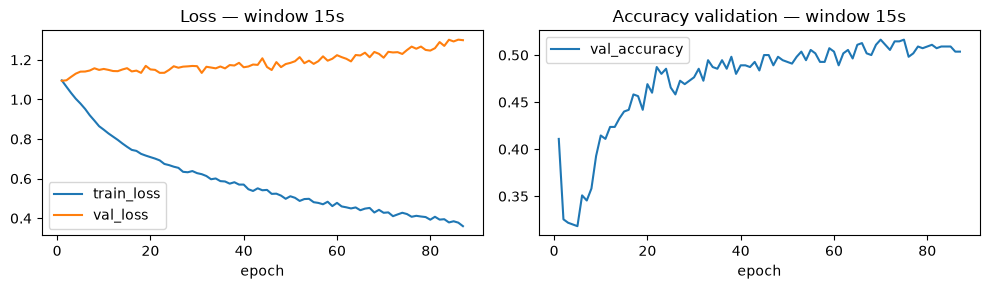

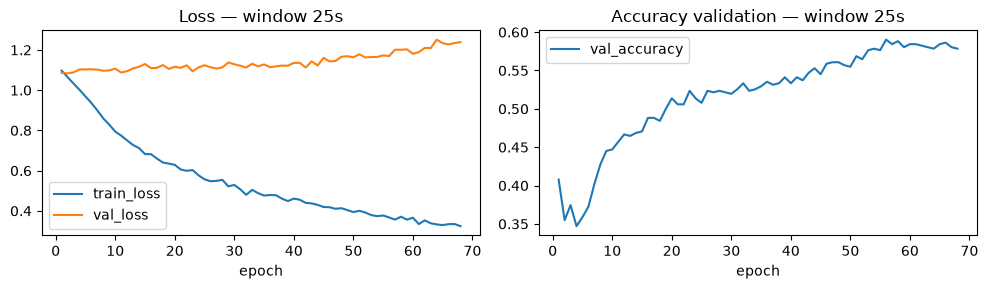

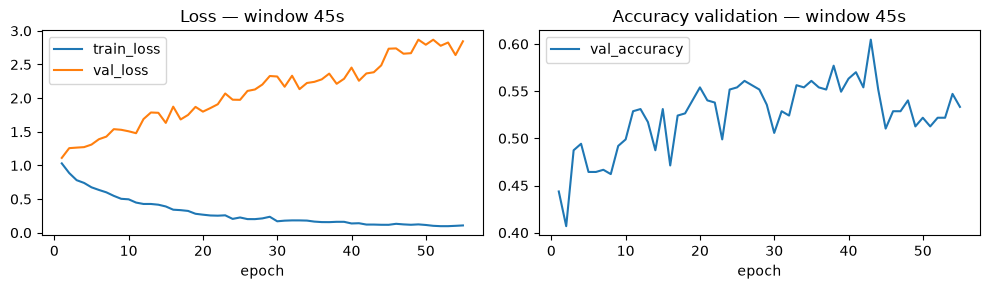

In [11]:
for window, view in views.items():
    train, validation = part_frame(view, "train"), part_frame(view, "validation")
    singles = [
        r
        for r in neural_records.values()
        if r["window"] == window and r["recipe"]["kind"] == "neural"
    ]
    leader = sorted(singles, key=rank_key)[0]
    seed_children = [leader]
    for seed in (17, 2026):
        config = copy.deepcopy(leader["recipe"]["config"])
        config["seed"] = seed
        seed_children.append(
            remember_neural(
                evaluate_neural_candidate(
                    store, window, config, train, validation, "seed_repeat"
                )
            )
        )
    remember_neural(
        neural_ensemble(
            store, window, seed_children, [1.0, 1.0, 1.0], validation, "seed_average"
        )
    )
    # Seed 17/2026 tidak menjadi kandidat tunggal untuk memilih seed yang kebetulan terbaik.
    architectures: dict[str, Any] = {}
    for record in sorted(singles, key=rank_key):
        architectures.setdefault(record["recipe"]["family"], record)
    pair = list(architectures.values())[:2]
    for weight in (0.25, 0.5, 0.75):
        remember_neural(
            neural_ensemble(
                store,
                window,
                pair,
                [weight, 1 - weight],
                validation,
                "architecture_voting",
            )
        )
    publish_leaderboard(store, neural_table(list(neural_records.values())))

neural_validation_table = neural_table(list(neural_records.values()))
display(neural_validation_table.round(4))
for window in (15, 25, 45):
    candidates = [
        r
        for r in neural_records.values()
        if r["window"] == window and r["stage"] == "neural_screening"
    ]
    leader = sorted(candidates, key=rank_key)[0]
    history = pd.read_csv(io.BytesIO(store.artifact(leader["id"], "history.csv")))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    history.plot(x="epoch", y=["train_loss", "val_loss"], ax=axes[0])
    history.plot(x="epoch", y="val_accuracy", ax=axes[1])
    axes[0].set_title(f"Loss — window {window}s")
    axes[1].set_title(f"Accuracy validation — window {window}s")
    plt.tight_layout()
    plt.show()
    store.publish(f"learning_curve_{window}s.png", figure_bytes(fig))

## Refit dan evaluasi test

Pilih satu kandidat setiap window berdasarkan accuracy validation, kemudian Macro-F1, kompleksitas, dan ID sebagai urutan tetap. Pemenang utama antarwindow juga ditetapkan sebelum test dibuka. Finalist di-fit ulang pada training + validation; test tidak ikut fitting. Untuk neural, jumlah epoch refit berasal dari checkpoint terbaik training sebelumnya.

Model yang disimpan adalah model yang benar-benar dievaluasi pada test. Hasil meliputi accuracy, Macro-F1, balanced accuracy, precision/recall per kelas, dan confusion matrix. Target accuracy 75% ditampilkan sebagai tercapai/belum tercapai, bukan syarat untuk mengubah split. Hasil antarwindow mempunyai jumlah test yang berbeda. Jangan mengganti pemenang utama berdasarkan tabel test.


Finalist dikunci dari validation sebelum evaluasi test:


,window,id,accuracy,macro_f1,balanced_accuracy
0,15,w15_be01358bfb41959422a3,0.516364,0.516050,0.540582
1,25,w25_94c819be066144f809b0,0.609804,0.610007,0.621104
2,45,w45_a3126a45dd04aa33dfe1,0.618391,0.586399,0.602821


  epoch 1/75: loss=1.0953
  epoch 10/75: loss=0.8434
  epoch 20/75: loss=0.7142
  epoch 30/75: loss=0.6357
  epoch 40/75: loss=0.5771
  epoch 50/75: loss=0.5388
  epoch 60/75: loss=0.4953
  epoch 70/75: loss=0.4570
Window 15s — test accuracy 47.41%, Macro-F1 47.02%; N=464
              precision  recall  f1-score   support
Low              0.4701  0.3901    0.4264  141.0000
Medium           0.4438  0.4104    0.4264  173.0000
High             0.5027  0.6267    0.5579  150.0000
accuracy         0.4741  0.4741    0.4741    0.4741
macro avg        0.4722  0.4757    0.4702  464.0000
weighted avg     0.4708  0.4741    0.4689  464.0000


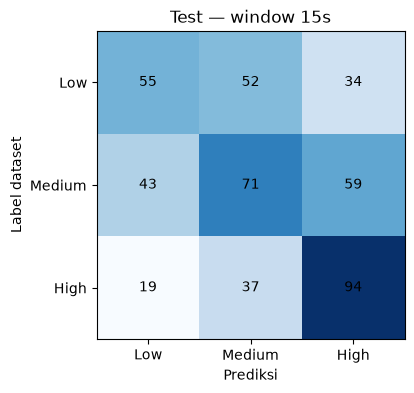

  epoch 1/56: loss=1.0925
  epoch 10/56: loss=0.7722
  epoch 20/56: loss=0.6237
  epoch 30/56: loss=0.5237
  epoch 40/56: loss=0.4687
  epoch 50/56: loss=0.4161
  epoch 1/39: loss=1.0543
  epoch 10/39: loss=0.6135
  epoch 20/39: loss=0.4675
  epoch 30/39: loss=0.3991
Window 25s — test accuracy 42.08%, Macro-F1 40.94%; N=423
              precision  recall  f1-score   support
Low              0.4272  0.3308    0.3729  133.0000
Medium           0.3652  0.2609    0.3043  161.0000
High             0.4488  0.7132    0.5509  129.0000
accuracy         0.4208  0.4208    0.4208    0.4208
macro avg        0.4137  0.4350    0.4094  423.0000
weighted avg     0.4102  0.4208    0.4011  423.0000


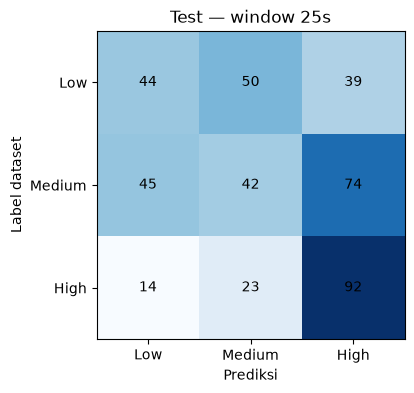

  epoch 1/43: loss=1.0348
  epoch 10/43: loss=0.4970
  epoch 20/43: loss=0.3287
  epoch 30/43: loss=0.2393
  epoch 40/43: loss=0.1791
  epoch 1/11: loss=1.0595
  epoch 10/11: loss=0.4866
Window 45s — test accuracy 45.86%, Macro-F1 45.82%; N=338
              precision  recall  f1-score   support
Low              0.5543  0.4080    0.4700  125.0000
Medium           0.3590  0.3818    0.3700  110.0000
High             0.4806  0.6019    0.5345  103.0000
accuracy         0.4586  0.4586    0.4586    0.4586
macro avg        0.4646  0.4639    0.4582  338.0000
weighted avg     0.4683  0.4586    0.4571  338.0000


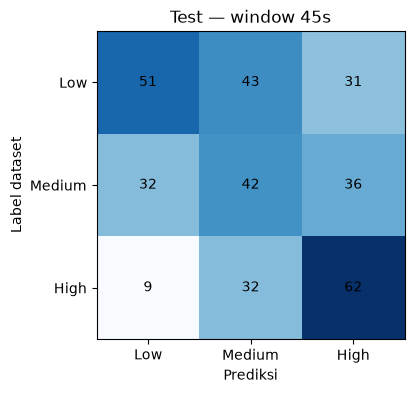

# Hasil run batch-03

Model utama dipilih berdasarkan validation: window 45 detik.

- Accuracy test: 45.86%
- Macro-F1 test: 45.82%
- Balanced accuracy test: 46.39%
- Jumlah test: 338
- Target accuracy 75%: belum tercapai

Model evaluasi: final_w45_a3126a45dd04aa33dfe1/model.pkl. Model ini di-fit pada training + validation, tidak pada test. Window lain merupakan pembanding yang telah ditetapkan sebelum evaluasi.

Split memakai blok waktu campuran dengan purge; data orang yang sama dapat muncul di training dan test. Hasil ini merupakan evaluasi internal dataset saat ini.



,window,primary,test_rows,accuracy,macro_f1,balanced_accuracy
0,15,False,464,0.4741,0.4702,0.4757
1,25,False,423,0.4208,0.4094,0.4350
2,45,True,338,0.4586,0.4582,0.4639


In [12]:
finalists = []
for window in (15, 25, 45):
    eligible = [
        r
        for r in neural_records.values()
        if r["window"] == window and r["stage"] != "seed_repeat"
    ]
    finalists.append(sorted(eligible, key=rank_key)[0])
print("Finalist dikunci dari validation sebelum evaluasi test:")
display(
    pd.DataFrame(
        [{"window": r["window"], "id": r["id"], **r["validation"]} for r in finalists]
    )
)
test_summary = final_evaluation(
    store, views, finalists, refit=refit_neural, predict=predict_neural
)
display(test_summary.round(4))

## Membaca ulang model hasil evaluasi

Contoh ini memuat model utama dari run yang sama dan menampilkan probabilitas. Tidak ada training baru. Muat hanya artefak terpercaya yang dibuat tim. Definisi dalam notebook ini tetap diperlukan untuk menjalankan contoh; tidak ada file kode pendamping yang harus diunggah.


In [13]:
# Contoh prediksi ulang model utama pada baris test yang sama, bukan training baru.
selected = store.read("selection")
final_key = "final_" + selected["primary_id"]
evaluated_model = load_bundle(store.artifact(final_key, "model.pkl"))
example = part_frame(views[selected["primary_window"]], "test").head(3)
probabilities = predict_neural(evaluated_model, example)
display(pd.DataFrame(probabilities, columns=LABELS))

,Low,Medium,High
0,0.021892,0.671327,0.306781
1,0.028208,0.744287,0.227505
2,0.254679,0.724304,0.021017
